In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report,
    f1_score, accuracy_score,
)
import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)

PLOTS_DIR = '/kaggle/working/ensemble_analysis'
os.makedirs(PLOTS_DIR, exist_ok=True)

LABEL_NAMES  = ['1★', '2★', '3★', '4★', '5★']
MODEL_NAMES  = ['BERT', 'RoBERTa-1e6', 'RoBERTa-2e6', 'ELECTRA', 'DistilBERT']
CLASS_COLORS = sns.color_palette('RdYlGn', n_colors=5)

def evaluation_score(preds, labels):
    mae = np.mean(np.abs(np.array(preds) - np.array(labels)))
    return 1.0 - mae / 4.0

print('Imports OK')

Imports OK


In [ ]:
NP_DIR = '/kaggle/input/datasets/vladcvx/bert-roberta-val-test-probs'

bert_probs_val       = np.load(f'{NP_DIR}/bert_probs_val.npy')
roberta1_probs_val   = np.load(f'{NP_DIR}/roberta_5_epochs_probs_val.npy')
roberta2_probs_val   = np.load(f'{NP_DIR}/roberta_2_epochs_higher_lr_probs_val.npy')
electra_probs_val    = np.load(f'{NP_DIR}/electra_probs_val.npy')
distilbert_probs_val = np.load(f'{NP_DIR}/distilbert_probs_val.npy')

all_probs = np.stack([
    bert_probs_val,
    roberta1_probs_val,
    roberta2_probs_val,
    electra_probs_val,
    distilbert_probs_val,
], axis=0)

ensemble_probs = all_probs.mean(axis=0)
ensemble_preds = ensemble_probs.argmax(axis=1)

model_preds = all_probs.argmax(axis=2)

print(f'Samples: {ensemble_probs.shape[0]:,}')
print(f'all_probs shape: {all_probs.shape}')

Samples: 25,200
all_probs shape: (5, 25200, 5)


In [ ]:
DATA_DIR = '/kaggle/input/datasets/vladcvx/sentiment-classification-data-256-roberta/data1'
train_df = pd.read_csv(f'{DATA_DIR}/train.csv')

import re
def clean_text(text):
    return re.sub(r'\s+', ' ', text).strip()
train_df['sentence'] = train_df['sentence'].apply(clean_text)

_, val_df = train_test_split(
    train_df,
    test_size=0.10,
    random_state=SEED,
    stratify=train_df['label'],
)
val_df = val_df.reset_index(drop=True)
val_labels = val_df['label'].values

assert len(val_labels) == len(ensemble_preds), (
    f"Mismatch: {len(val_labels)} labels vs {len(ensemble_preds)} preds — "
    "check that VAL_SIZE=0.10 and SEED=42 match your ensemble notebook"
)
print(f'Val labels loaded: {len(val_labels):,}')

Val labels loaded: 25,200


In [ ]:
rows = []
for i, name in enumerate(MODEL_NAMES):
    preds = model_preds[i]
    rows.append({
        'Model'   : name,
        'Score'   : round(evaluation_score(preds, val_labels), 4),
        'Accuracy': round(accuracy_score(val_labels, preds), 4),
        'F1 (macro)': round(f1_score(val_labels, preds, average='macro'), 4),
        'F1 (weighted)': round(f1_score(val_labels, preds, average='weighted'), 4),
    })

rows.append({
    'Model'   : 'Ensemble (avg)',
    'Score'   : round(evaluation_score(ensemble_preds, val_labels), 4),
    'Accuracy': round(accuracy_score(val_labels, ensemble_preds), 4),
    'F1 (macro)': round(f1_score(val_labels, ensemble_preds, average='macro'), 4),
    'F1 (weighted)': round(f1_score(val_labels, ensemble_preds, average='weighted'), 4),
})

perf_df = pd.DataFrame(rows).set_index('Model')
display(perf_df.style.highlight_max(axis=0, color='#c8f7c5')
                     .highlight_min(axis=0, color='#f7c5c5')
                     .format('{:.4f}'))

,Score,Accuracy,F1 (macro),F1 (weighted)
Model,,,,
BERT,0.9007,0.6518,0.6501,0.6501
RoBERTa-1e6,0.9079,0.6686,0.6662,0.6662
RoBERTa-2e6,0.9084,0.6669,0.6662,0.6662
ELECTRA,0.8946,0.6359,0.6323,0.6323
DistilBERT,0.8947,0.6312,0.6312,0.6312
Ensemble (avg),0.9081,0.6687,0.6671,0.6671


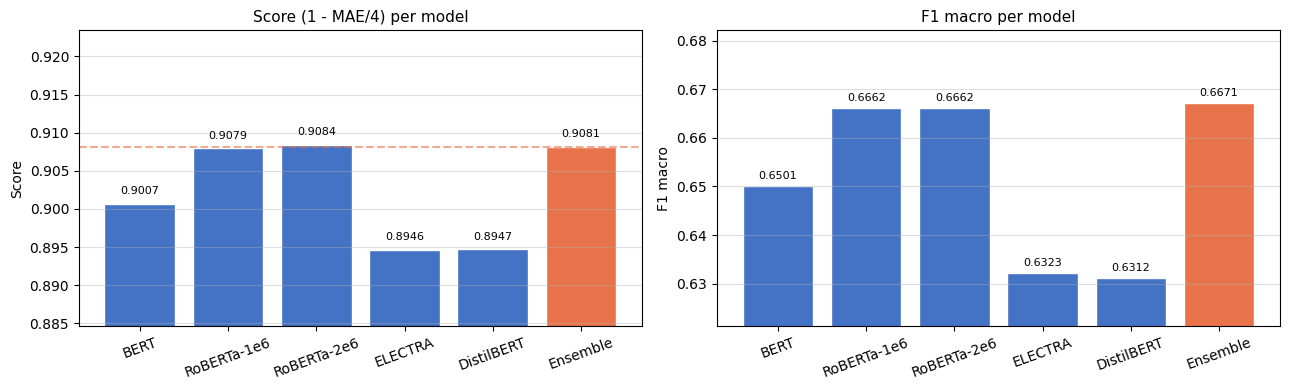

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

models_all = MODEL_NAMES + ['Ensemble']
scores     = [evaluation_score(model_preds[i], val_labels) for i in range(5)]
scores.append(evaluation_score(ensemble_preds, val_labels))
colors     = ['#4472C4'] * 5 + ['#E8734A']

bars = axes[0].bar(models_all, scores, color=colors, edgecolor='white')
for bar, s in zip(bars, scores):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                 f'{s:.4f}', ha='center', va='bottom', fontsize=8)
axes[0].set_title('Score (1 - MAE/4) per model', fontsize=11)
axes[0].set_ylabel('Score')
axes[0].set_ylim(min(scores) - 0.01, max(scores) + 0.015)
axes[0].tick_params(axis='x', rotation=20)
axes[0].grid(axis='y', alpha=0.4)
axes[0].axhline(scores[-1], color='#E8734A', linestyle='--', alpha=0.6, label='Ensemble')

f1s = [f1_score(val_labels, model_preds[i], average='macro') for i in range(5)]
f1s.append(f1_score(val_labels, ensemble_preds, average='macro'))
bars2 = axes[1].bar(models_all, f1s, color=colors, edgecolor='white')
for bar, s in zip(bars2, f1s):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                 f'{s:.4f}', ha='center', va='bottom', fontsize=8)
axes[1].set_title('F1 macro per model', fontsize=11)
axes[1].set_ylabel('F1 macro')
axes[1].set_ylim(min(f1s) - 0.01, max(f1s) + 0.015)
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

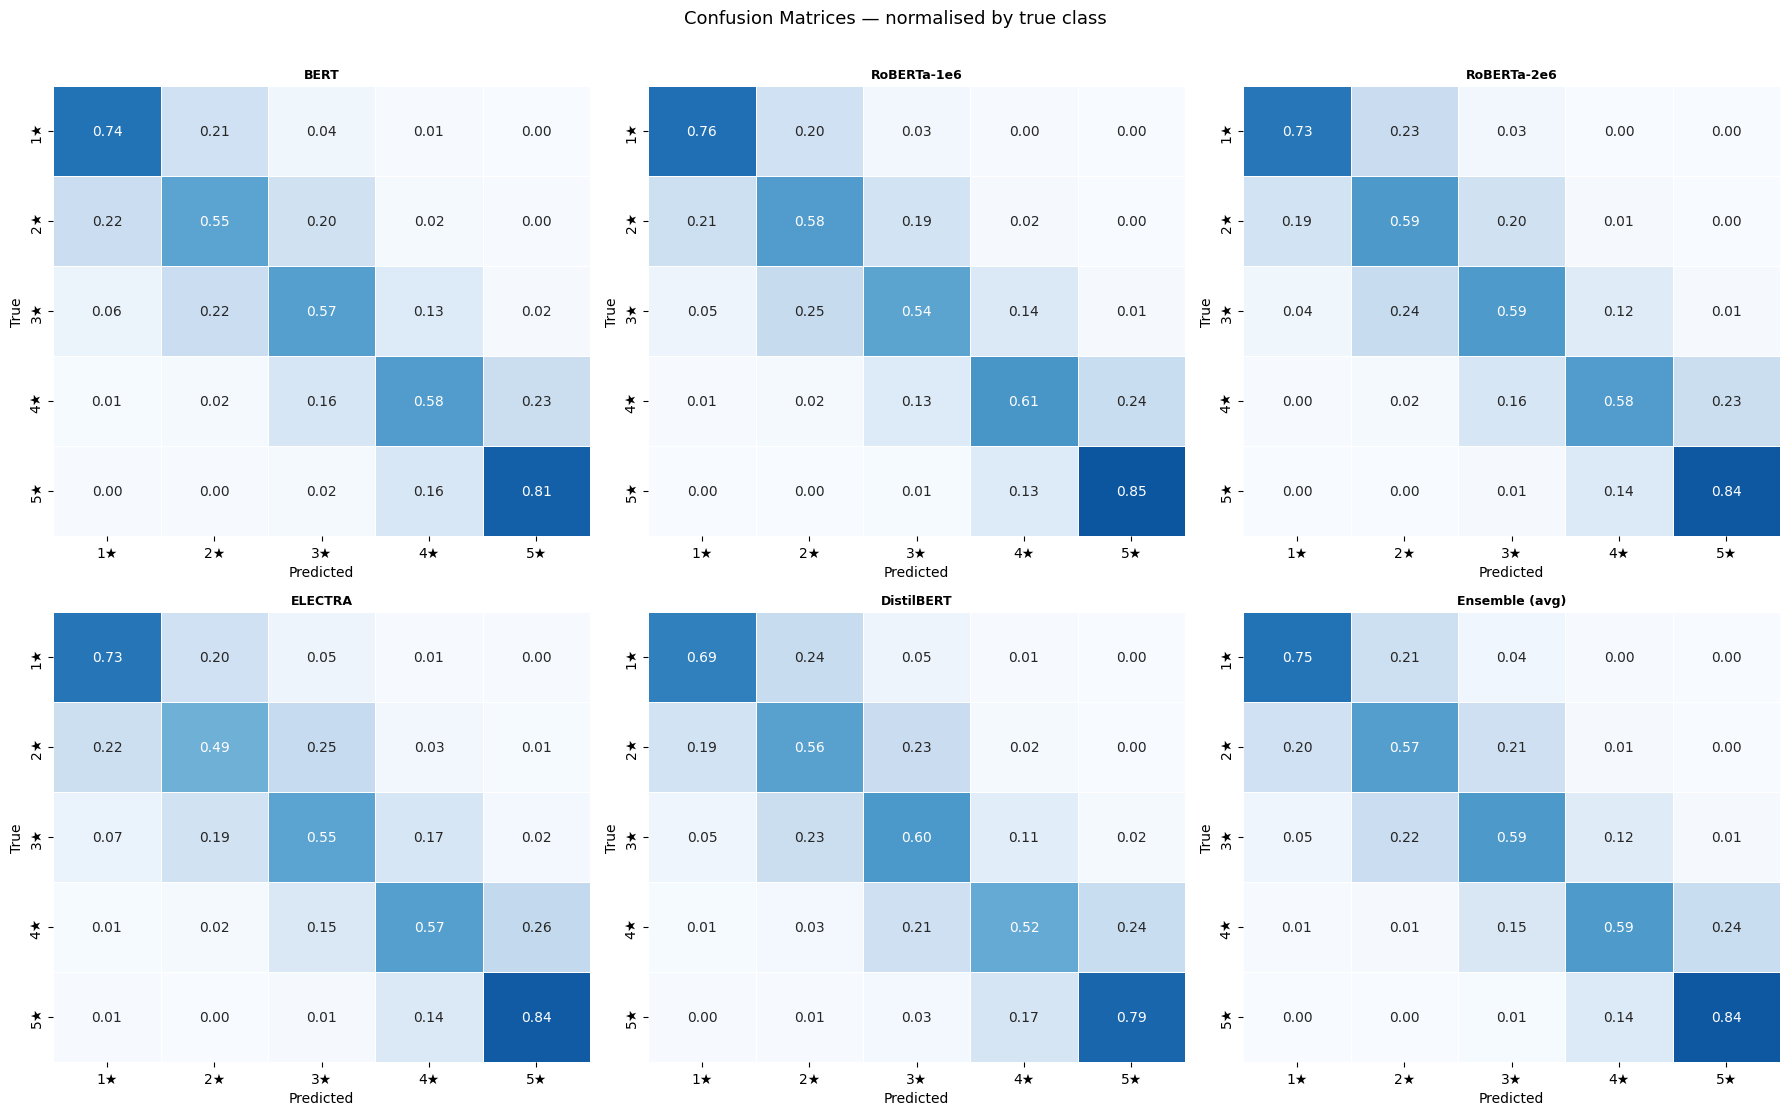

In [6]:
def plot_cm(preds, labels, title, ax, normalize=True):
    cm = confusion_matrix(labels, preds)
    if normalize:
        cm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm, annot=True,
                fmt='.2f' if normalize else 'd',
                cmap='Blues', ax=ax,
                xticklabels=LABEL_NAMES,
                yticklabels=LABEL_NAMES,
                vmin=0, vmax=1 if normalize else None,
                linewidths=0.5, cbar=False)
    ax.set_title(title, fontsize=9, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

n_models = len(MODEL_NAMES)
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, name in enumerate(MODEL_NAMES):
    plot_cm(model_preds[i], val_labels, name, axes[i])

plot_cm(ensemble_preds, val_labels, 'Ensemble (avg)', axes[5])

plt.suptitle('Confusion Matrices — normalised by true class', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/confusion_matrices_all.png', dpi=150, bbox_inches='tight')
plt.show()

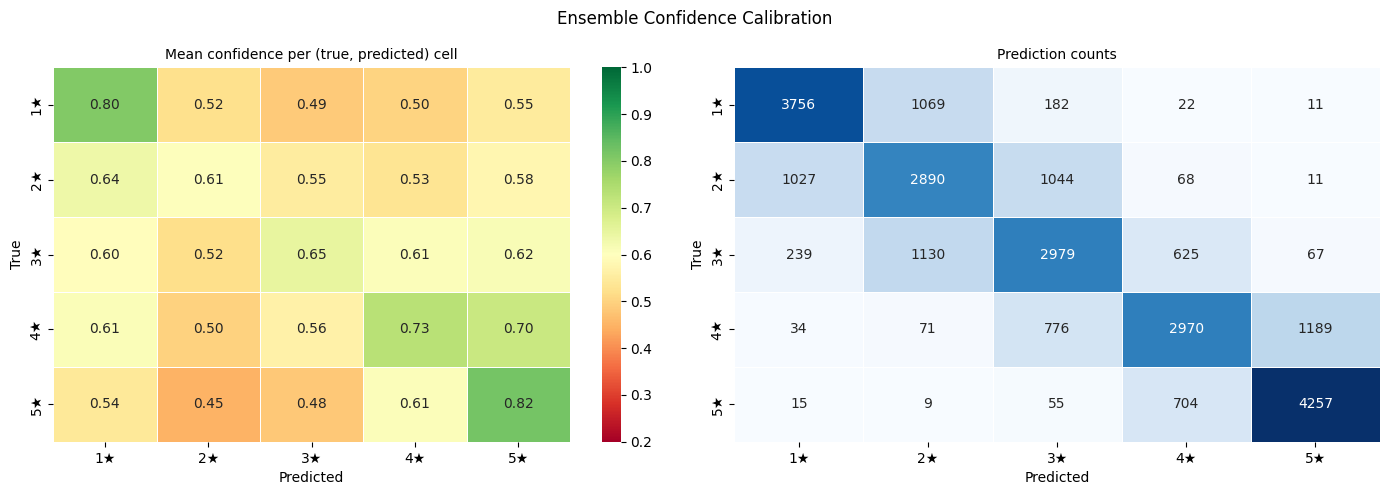

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

conf_matrix = np.zeros((5, 5))
count_matrix = np.zeros((5, 5))
max_conf = ensemble_probs.max(axis=1)

for true, pred, conf in zip(val_labels, ensemble_preds, max_conf):
    conf_matrix[true, pred]  += conf
    count_matrix[true, pred] += 1

with np.errstate(invalid='ignore'):
    mean_conf = np.where(count_matrix > 0, conf_matrix / count_matrix, 0)

sns.heatmap(mean_conf, annot=True, fmt='.2f', cmap='RdYlGn',
            xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES,
            vmin=0.2, vmax=1.0, ax=axes[0], linewidths=0.5)
axes[0].set_title('Mean confidence per (true, predicted) cell', fontsize=10)
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

cm_raw = confusion_matrix(val_labels, ensemble_preds)
sns.heatmap(cm_raw, annot=True, fmt='d', cmap='Blues',
            xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES,
            ax=axes[1], linewidths=0.5, cbar=False)
axes[1].set_title('Prediction counts', fontsize=10)
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('True')

plt.suptitle('Ensemble Confidence Calibration', fontsize=12)
plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/confidence_calibration.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
agreement = (model_preds == ensemble_preds[None, :]).sum(axis=0)

val_df['ensemble_pred'] = ensemble_preds
val_df['agreement']     = agreement
val_df['correct']       = (ensemble_preds == val_labels)
val_df['true_label']    = val_labels
val_df['max_conf']      = max_conf
val_df['pred_error']    = np.abs(ensemble_preds - val_labels)

for k in range(6):
    n = (agreement == k).sum()
    pct = n / len(agreement) * 100
    sc  = evaluation_score(ensemble_preds[agreement == k], val_labels[agreement == k]) if n > 0 else float('nan')
    print(f'{k}/5 models agree: {n:>6,} samples ({pct:5.1f}%)  score={sc:.4f}')

0/5 models agree:      6 samples (  0.0%)  score=0.7917
1/5 models agree:     96 samples (  0.4%)  score=0.8047
2/5 models agree:  1,060 samples (  4.2%)  score=0.8387
3/5 models agree:  3,170 samples ( 12.6%)  score=0.8545
4/5 models agree:  4,666 samples ( 18.5%)  score=0.8820
5/5 models agree: 16,202 samples ( 64.3%)  score=0.9314


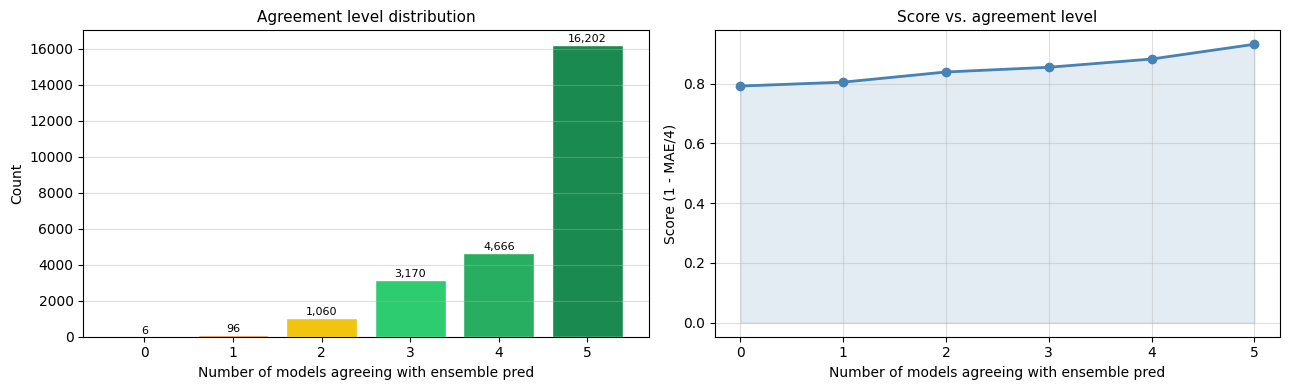

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

agree_counts = [(agreement == k).sum() for k in range(6)]
bar_colors   = ['#e74c3c','#e67e22','#f1c40f','#2ecc71','#27ae60','#1a8a50']
bars = axes[0].bar(range(6), agree_counts, color=bar_colors, edgecolor='white')
for bar, n in zip(bars, agree_counts):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                 f'{n:,}', ha='center', va='bottom', fontsize=8)
axes[0].set_title('Agreement level distribution', fontsize=11)
axes[0].set_xlabel('Number of models agreeing with ensemble pred')
axes[0].set_ylabel('Count')
axes[0].set_xticks(range(6))
axes[0].grid(axis='y', alpha=0.4)

agree_scores = []
for k in range(6):
    mask = agreement == k
    if mask.sum() > 0:
        agree_scores.append(evaluation_score(ensemble_preds[mask], val_labels[mask]))
    else:
        agree_scores.append(0)

axes[1].plot(range(6), agree_scores, marker='o', color='steelblue', linewidth=2)
axes[1].fill_between(range(6), agree_scores, alpha=0.15, color='steelblue')
axes[1].set_title('Score vs. agreement level', fontsize=11)
axes[1].set_xlabel('Number of models agreeing with ensemble pred')
axes[1].set_ylabel('Score (1 - MAE/4)')
axes[1].set_xticks(range(6))
axes[1].grid(alpha=0.4)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/disagreement_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

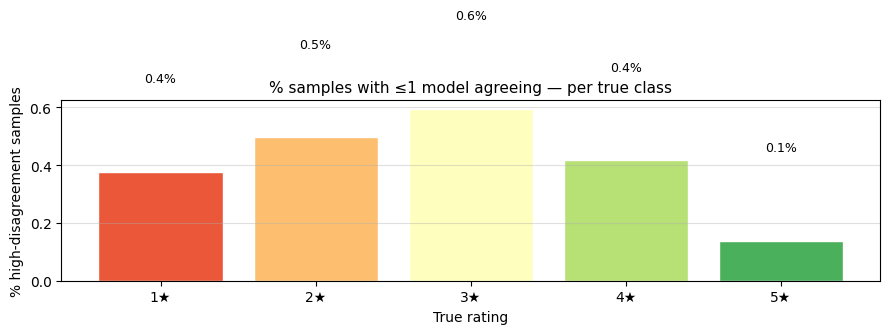

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
full_disagree_rate = []
for label in range(5):
    mask = val_labels == label
    rate = (agreement[mask] <= 1).mean() * 100
    full_disagree_rate.append(rate)

bars = ax.bar(LABEL_NAMES, full_disagree_rate, color=CLASS_COLORS, edgecolor='white')
for bar, r in zip(bars, full_disagree_rate):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{r:.1f}%', ha='center', va='bottom', fontsize=9)
ax.set_title('% samples with ≤1 model agreeing — per true class', fontsize=11)
ax.set_xlabel('True rating')
ax.set_ylabel('% high-disagreement samples')
ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/disagreement_per_class.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
for i, name in enumerate(MODEL_NAMES):
    val_df[f'pred_{name}'] = model_preds[i]

pd.set_option('display.max_colwidth', 180)
PRED_COLS = ['sentence', 'true_label', 'ensemble_pred', 'agreement', 'correct'] +             [f'pred_{n}' for n in MODEL_NAMES]

for label in range(5):
    subset = val_df[
        (val_df['true_label'] == label) &
        (val_df['agreement'] <= 1)
    ].copy()

    if len(subset) == 0:
        print(f'{LABEL_NAMES[label]}: no high-disagreement samples')
        continue

    correct_ex   = subset[subset['correct']].head(3)
    incorrect_ex = subset[~subset['correct']].head(3)

    print(f'\n{"="*70}')
    print(f'True class: {LABEL_NAMES[label]}  |  High-disagreement samples')
    print(f'  Total: {len(subset)} | Correct: {subset["correct"].sum()} | '
          f'Incorrect: {(~subset["correct"]).sum()}')
    print(f'{"="*70}')

    if len(correct_ex):
        print('\n--- Ensemble CORRECT despite disagreement ---')
        display(correct_ex[PRED_COLS].rename(
            columns={f'pred_{n}': n for n in MODEL_NAMES}))

    if len(incorrect_ex):
        print('\n--- Ensemble INCORRECT ---')
        display(incorrect_ex[PRED_COLS].rename(
            columns={f'pred_{n}': n for n in MODEL_NAMES}))


True class: 1★  |  High-disagreement samples
  Total: 19 | Correct: 2 | Incorrect: 17

--- Ensemble CORRECT despite disagreement ---


,sentence,true_label,ensemble_pred,agreement,correct,BERT,RoBERTa-1e6,RoBERTa-2e6,ELECTRA,DistilBERT
21726,Gutes Gerät..doch leider defekt und Lieferant reagiert nicht Gerät nach 8 Monaten defekt und der Lieferant reagiert leider nicht. Gehe nun direkt über Severin GmbH. Bernd Blase...,0,0,1,True,2,0,1,2,1
22950,Eine ältere Auflage zugeschickt bekommen als bestellt. Ich habe die 58. Auflage bestellt. Aber eine 56 bekommen.,0,0,1,True,2,1,1,0,2



--- Ensemble INCORRECT ---


,sentence,true_label,ensemble_pred,agreement,correct,BERT,RoBERTa-1e6,RoBERTa-2e6,ELECTRA,DistilBERT
11,This is a long wait!! Hope it’s I. Good condition!! Still waiting for this cd of movie!! Why taking so long??,0,3,1,False,4,3,2,2,4
546,Verkoppelung nicht funktiontüchtig! Die uhr ist echt wunderschön und war als geb Geschenk für eine Freundin gedacht. Doch wie es herausstellt funktioniert die verkoppelung auf ...,0,1,1,False,1,0,0,2,2
4080,"Aufnahme von wegen Ich hab extra 65 zoll und Aufnahme gesucht und ein Rezension Schreiber hat gesagt, die Aufnahme ist perfekt, also hab ich es gekauft, doch war es nicht zu Au...",0,2,0,False,3,1,1,4,3



True class: 2★  |  High-disagreement samples
  Total: 25 | Correct: 11 | Incorrect: 14

--- Ensemble CORRECT despite disagreement ---


...

,sentence,true_label,ensemble_pred,agreement,correct,BERT,RoBERTa-1e6,RoBERTa-2e6,ELECTRA,DistilBERT
1816,"Die Deutsche Sprache wäre echt eine feine Sache Die Fernbedienung funktioniert überhaupt nicht, auch mit neue Batterie, Zum glück gibt es ja Handy und eine App wo mann auch nic...",3,1,1,False,0,2,2,4,1
4262,"Auflagenbox für einen angemessenen Preis, mehr aber auch nicht. Die Box ist aus sehr dünnem Blech, welches beim Zsammenbau an Stabilität gewinnt. Die Konstruktion ist durchdach...",3,2,1,False,2,3,3,1,3
8068,"For storage only, not for pumping into. Read more carefully than I did. These bags are not for pumping directly into as there is no way to attach them to the adapter. You have ...",3,2,1,False,1,1,1,2,1



True class: 5★  |  High-disagreement samples
  Total: 7 | Correct: 1 | Incorrect: 6

--- Ensemble CORRECT despite disagreement ---


,sentence,true_label,ensemble_pred,agreement,correct,BERT,RoBERTa-1e6,RoBERTa-2e6,ELECTRA,DistilBERT
1564,"gut Qualität passt super, ist zu meiner zufriedenheit relativ hoch geschnitten, damit sie nicht beim fahren in fast horizontaler lage verrutscht. Sitzt gut und trägt nicht so s...",4,4,1,True,3,3,3,4,3



--- Ensemble INCORRECT ---


,sentence,true_label,ensemble_pred,agreement,correct,BERT,RoBERTa-1e6,RoBERTa-2e6,ELECTRA,DistilBERT
2710,"Simple, but great read! This is a book that I would call an “easy read”, but I would call it that with hesitation to not make it seem like it isn’t an amazing book. I loved bei...",4,3,1,False,2,4,4,4,3
4798,"Hallo wach! Das Produkt schmeckt nicht sonderlich gut, dafür ist die Wirkung umso phänomenaler! Man ist kurze Zeit nach dem Trinken super wach! Hoch dosiertes Koffein, mit viel...",4,2,1,False,1,3,3,2,1
6470,Außenleuchte Wegleuchte FÜR DEN PREIS UNSCHLAGBAR,4,3,1,False,4,4,3,4,4


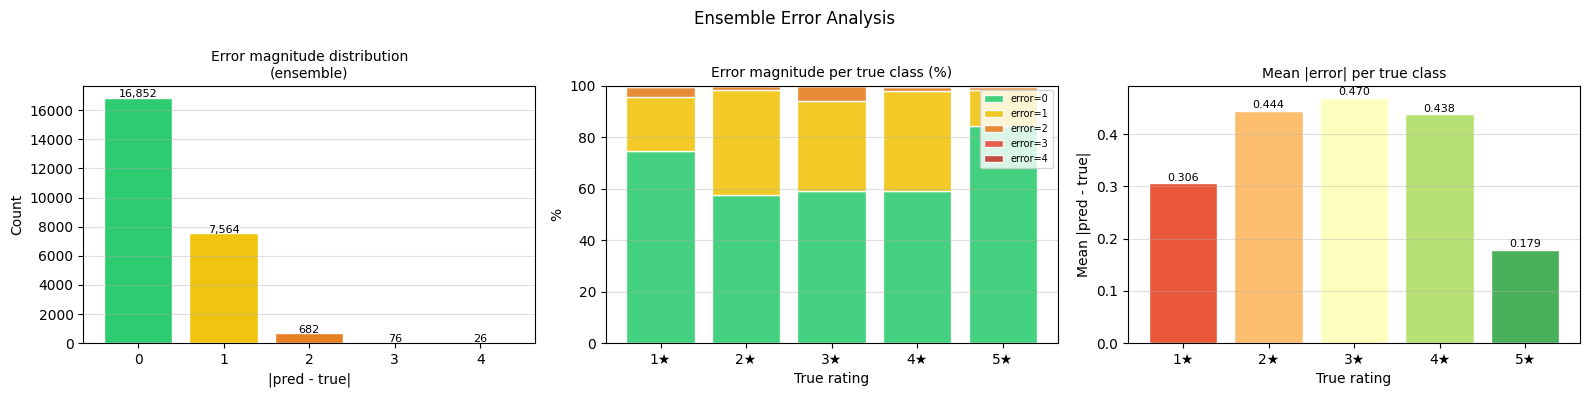


Correct (error=0): 16,852 (66.9%)
Off-by-1:          7,564 (30.0%)
Off-by-2:          682 (2.7%)
Off-by-3+:         102 (0.4%)


In [ ]:
errors = np.abs(ensemble_preds - val_labels)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

err_counts = [(errors == e).sum() for e in range(5)]
axes[0].bar(range(5), err_counts,
            color=['#2ecc71','#f1c40f','#e67e22','#e74c3c','#c0392b'],
            edgecolor='white')
axes[0].set_title('Error magnitude distribution\n(ensemble)', fontsize=10)
axes[0].set_xlabel('|pred - true|')
axes[0].set_ylabel('Count')
axes[0].set_xticks(range(5))
axes[0].grid(axis='y', alpha=0.4)
for i, n in enumerate(err_counts):
    axes[0].text(i, n + 30, f'{n:,}', ha='center', fontsize=8)

err_by_class = np.zeros((5, 5))
for true in range(5):
    mask = val_labels == true
    for e in range(5):
        err_by_class[true, e] = (errors[mask] == e).sum()

err_by_class_pct = err_by_class / err_by_class.sum(axis=1, keepdims=True) * 100
bottom = np.zeros(5)
err_colors = ['#2ecc71','#f1c40f','#e67e22','#e74c3c','#c0392b']
for e in range(5):
    axes[1].bar(LABEL_NAMES, err_by_class_pct[:, e],
                bottom=bottom, color=err_colors[e],
                label=f'error={e}', edgecolor='white', alpha=0.9)
    bottom += err_by_class_pct[:, e]
axes[1].set_title('Error magnitude per true class (%)', fontsize=10)
axes[1].set_xlabel('True rating')
axes[1].set_ylabel('%')
axes[1].legend(fontsize=7, loc='upper right')
axes[1].grid(axis='y', alpha=0.4)

mean_err = [errors[val_labels == c].mean() for c in range(5)]
axes[2].bar(LABEL_NAMES, mean_err, color=CLASS_COLORS, edgecolor='white')
axes[2].set_title('Mean |error| per true class', fontsize=10)
axes[2].set_xlabel('True rating')
axes[2].set_ylabel('Mean |pred - true|')
axes[2].grid(axis='y', alpha=0.4)
for i, v in enumerate(mean_err):
    axes[2].text(i, v + 0.005, f'{v:.3f}', ha='center', fontsize=8)

plt.suptitle('Ensemble Error Analysis', fontsize=12)
plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/error_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'\nCorrect (error=0): {(errors==0).sum():,} ({(errors==0).mean()*100:.1f}%)')
print(f'Off-by-1:          {(errors==1).sum():,} ({(errors==1).mean()*100:.1f}%)')
print(f'Off-by-2:          {(errors==2).sum():,} ({(errors==2).mean()*100:.1f}%)')
print(f'Off-by-3+:         {(errors>=3).sum():,} ({(errors>=3).mean()*100:.1f}%)')

In [13]:
wrong_mask = ensemble_preds != val_labels
wrong_true = val_labels[wrong_mask]
wrong_pred = ensemble_preds[wrong_mask]

pair_counts = {}
for t, p in zip(wrong_true, wrong_pred):
    pair_counts[(int(t), int(p))] = pair_counts.get((int(t), int(p)), 0) + 1

top_pairs = sorted(pair_counts.items(), key=lambda x: -x[1])[:15]

print('Top confused (true → pred) pairs:')
print(f'{"True":>10}  {"Pred":>10}  {"Count":>8}  {"% of errors":>12}')
print('-' * 46)
total_errors = wrong_mask.sum()
for (t, p), cnt in top_pairs:
    print(f'{LABEL_NAMES[t]:>10}  {LABEL_NAMES[p]:>10}  {cnt:>8,}  {cnt/total_errors*100:>11.1f}%')

Top confused (true → pred) pairs:
      True        Pred     Count   % of errors
----------------------------------------------
        4★          5★     1,189         14.2%
        3★          2★     1,130         13.5%
        1★          2★     1,069         12.8%
        2★          3★     1,044         12.5%
        2★          1★     1,027         12.3%
        4★          3★       776          9.3%
        5★          4★       704          8.4%
        3★          4★       625          7.5%
        3★          1★       239          2.9%
        1★          3★       182          2.2%
        4★          2★        71          0.9%
        2★          4★        68          0.8%
        3★          5★        67          0.8%
        5★          3★        55          0.7%
        4★          1★        34          0.4%


In [ ]:
top_pair = top_pairs[0][0]
t, p = top_pair

examples = val_df[
    (val_df['true_label'] == t) &
    (val_df['ensemble_pred'] == p)
].sample(min(5, (val_df['true_label'] == t).sum()), random_state=SEED)

print(f'\nExample reviews: True={LABEL_NAMES[t]}, Predicted={LABEL_NAMES[p]}')
print('='*70)
for _, row in examples.iterrows():
    print(f'  [{row["agreement"]}/5 agree]  {row["sentence"][:200]}')
    print()


Example reviews: True=4★, Predicted=5★
  [5/5 agree]  Top zweckmäßige und sinnvolle Anschaffung, einfache Handhabung

  [3/5 agree]  Buy it This item is pretty cool. Is very portable.

  [5/5 agree]  Sehr zufrieden!!! Die Babybliss Warmluftbürste ist sehr empfehlenswert. Ich verwende sie gerne und jeden Tag. Sie trocknet die Haare schnell, aber definitiv schonender, wenn man nur einen normalen Föh

  [5/5 agree]  I NEVER buy paper towels I use these cloths for everything and then just throw them in the wash. Great!

  [5/5 agree]  Nice! I got these because i saw them featured (not this particular brand) on a talk show. They are nice, and will keep out the sun from damaging your eyes and causing wrinkles....very cool!

